Importing files

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

Reading the Data file 

In [2]:
df = pd.read_csv('Data_file.csv')

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41,880,129.0,322,126,8.3252,452600,NEAR BAY
1,-122.22,37.86,21,7099,1106.0,2401,1138,8.3014,358500,NEAR BAY
2,-122.24,37.85,52,1467,190.0,496,177,7.2574,352100,NEAR BAY
3,-122.25,37.85,52,1274,235.0,558,219,5.6431,341300,NEAR BAY
4,-122.25,37.85,52,1627,280.0,565,259,3.8462,342200,NEAR BAY


Understanding the structure of the data

In [3]:
df.shape

(20640, 10)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  int64  
 3   total_rooms         20640 non-null  int64  
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  int64  
 6   households          20640 non-null  int64  
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  int64  
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(4), int64(5), object(1)
memory usage: 1.6+ MB


In [5]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [6]:
df.isnull().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

## Visualization
Distribution of House Values using histogram

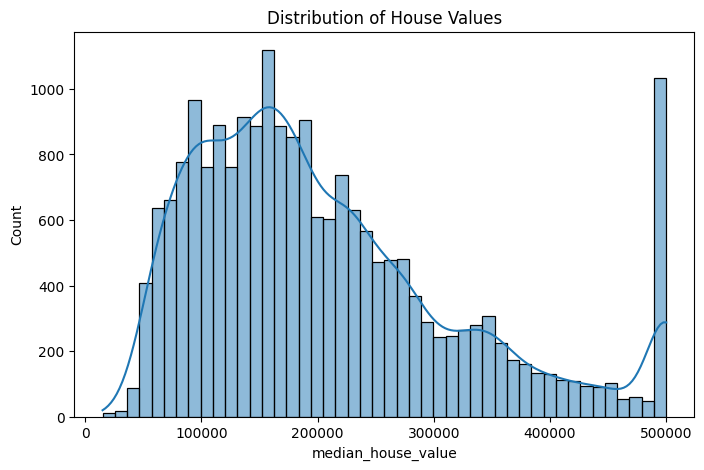

In [7]:
plt.figure(figsize=(8,5))
sns.histplot(df['median_house_value'], kde=True)
plt.title("Distribution of House Values")
plt.show()

Median Income vs House Value using scatter plot

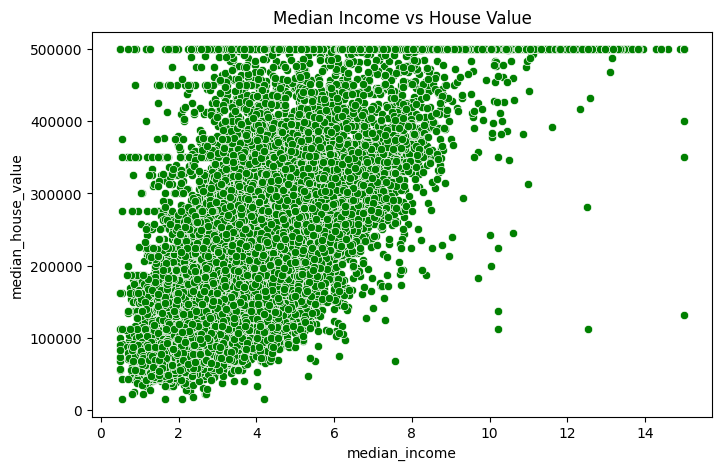

In [8]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x='median_income',
    y='median_house_value',
    data=df,
    color = 'green'
) 
plt.title("Median Income vs House Value")
plt.show()

Correlation Heatmap:

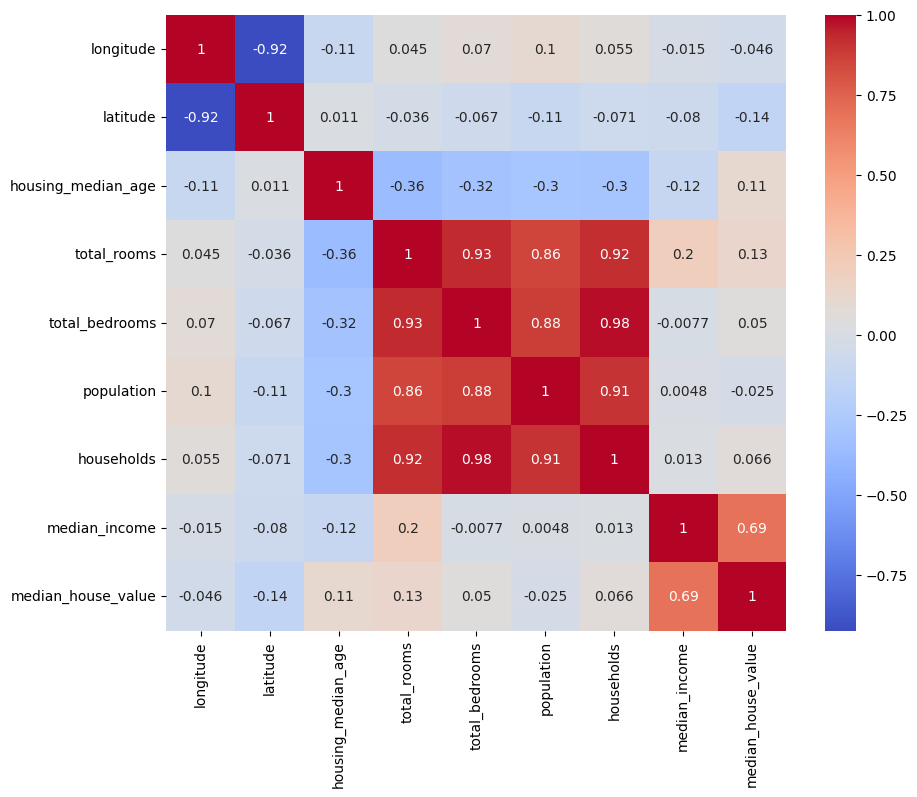

In [9]:
plt.figure(figsize=(10,8))
sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)
plt.show()

# Data Preprocessing 

Missing values:

In [10]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(
    df['total_bedrooms'].median()
)

Encode Categorical Variable

In [11]:
df = pd.get_dummies(
    df,
    columns=['ocean_proximity'],
    drop_first=True
)

# Simple Linear Regression

In [12]:
X = df[['median_income']]
y = df['median_house_value']

Split:

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

Train:

In [14]:
simple_model = LinearRegression()

simple_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


predict:

In [15]:
y_pred_simple = simple_model.predict(X_test)

Evaluate:

In [16]:
mse = mean_squared_error(y_test, y_pred_simple)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_simple)

print("MSE:", mse)
print("RMSE:", rmse)
print("R²:", r2)

MSE: 7091157771.76555
RMSE: 84209.01241414454
R²: 0.45885918903846656


# multiple Linear Regression

Features:

split, train:

In [25]:
X1 = df.drop('median_house_value', axis = 1)
Y1 = df['median_house_value']

X1_train, X1_test, Y1_train, Y1_test = train_test_split(
    X1,
    Y1,
    test_size=0.2,
    random_state=42
)

predict:

In [27]:
multi_model = LinearRegression()
multi_model.fit(X1_train, Y1_train)
Y_pred_multi = multi_model.predict(X1_test)

Evaluate:

In [28]:
mse = mean_squared_error(Y1_test, Y_pred_multi)
rmse = np.sqrt(mse)
r2 = r2_score(Y1_test, Y_pred_multi)

print("MSE: ", mse)
print("RMSE: ", rmse)
print("R^2: ", r2)

MSE:  4908476721.156648
RMSE:  70060.52184473541
R^2:  0.6254240620553582


# Model Comparison

In [ ]:
#model                           RMSE                R^2 
#simple Linear Regression        84209.01241414454   0.45885918903846656
#Multiple Linear Regression      70060.52184473541   0.6254240620553582

# Conclusion
 Two regression models were developed to pridict medain house values. The Simple Linear Regression Model used only median_income as the predictor, while the Multiple Linear Regression model used all avalable features. The Multiple Linear Regression Model achieved a lower RMSE (70060.52) and a higher R^2 score (0.6254) comapred to the Simple Linear Regression model provided more accurate predictions and better explained the variation in house prices.